In [29]:
# 1. 必要なシステムのパッケージ（Chromeブラウザ等）をインストール
!apt-get update
!apt-get install -y chromium-chromedriver

# 2. Pythonライブラリのインストール
!pip install selenium

import selenium
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.chrome.service import Service

# Chromeのオプションを設定（Colab環境用に必須のヘッドレス設定）
chrome_options = Options()
chrome_options.add_argument('--headless')
chrome_options.add_argument('--no-sandbox')
chrome_options.add_argument('--disable-dev-shm-usage')

# インストールしたchromedriverのパスを指定して初期化
# Colabのaptで入るchromedriverは通常以下のパスになります
service = Service(executable_path='/usr/lib/chromium-browser/chromedriver')
chrome_driver = webdriver.Chrome(service=service, options=chrome_options)

url = "https://www.nikkei.com/smartchart/?code=N101/T&timeframe=6m&interval=1Day&eventsShow=1"

chrome_driver.get(url)

print("現在のURL:", chrome_driver.current_url)
print("ページタイトル:", chrome_driver.title)


Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  apparmor chromium-browser libfuse3-3 snapd squashfs-tools systemd-hwe-hwdb
  udev
Suggested packages:
  apparmor-pr

WebDriverException: Message: Service /usr/lib/chromium-browser/chromedriver unexpectedly exited. Status code was: 1


In [3]:
!which google-chrome
!which chromedriver

In [4]:
!ls -l /content/chrome-linux64/chrome
!ls -l /content/chromedriver-linux64/chromedriver

ls: cannot access '/content/chrome-linux64/chrome': No such file or directory
ls: cannot access '/content/chromedriver-linux64/chromedriver': No such file or directory


In [5]:
!apt-get update -qq
!apt-get install -y -qq wget unzip libatk1.0-0t64 libatk-bridge2.0-0t64 libatspi2.0-0t64 libxcomposite1

from selenium import webdriver
from selenium.webdriver.chrome.service import Service

# Selenium ManagerがChromeを準備・管理する
options = webdriver.ChromeOptions()
options.add_argument("--headless=new")
options.add_argument("--no-sandbox")
options.add_argument("--disable-dev-shm-usage")

driver = webdriver.Chrome(options=options)

print("Chromeの起動に成功しました")
print("ブラウザ:", driver.capabilities["browserName"])
print("バージョン:", driver.capabilities["browserVersion"])

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package at-spi2-common.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../0-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../1-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../2-libxtst6_2%3a1.2.3-1.1ubuntu0.1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1.2.3-1.1ubuntu0.1) ...
Selecting previously unselected package session-migration.
Preparing to unpack .../3-session-migration_0.3.9build1_amd64.deb ...
Unpacking session-migration (0.3.9build1) ...
Selecting previously un

In [6]:
url = "https://www.nikkei.com/smartchart/?code=N101/T&timeframe=6m&interval=1Day&eventsShow=1"

driver.get(url)

print("現在のURL:", driver.current_url)
print("ページタイトル:", driver.title)

現在のURL: https://www.nikkei.com/smartchart/?code=N101%2FT&timeframe=6m&interval=1Day&upperIndicators=sma&lowerIndicators=volume&eventsShow=1
ページタイトル: 日経平均株価 : 指数 : スマートチャートプラス : 日経電子版


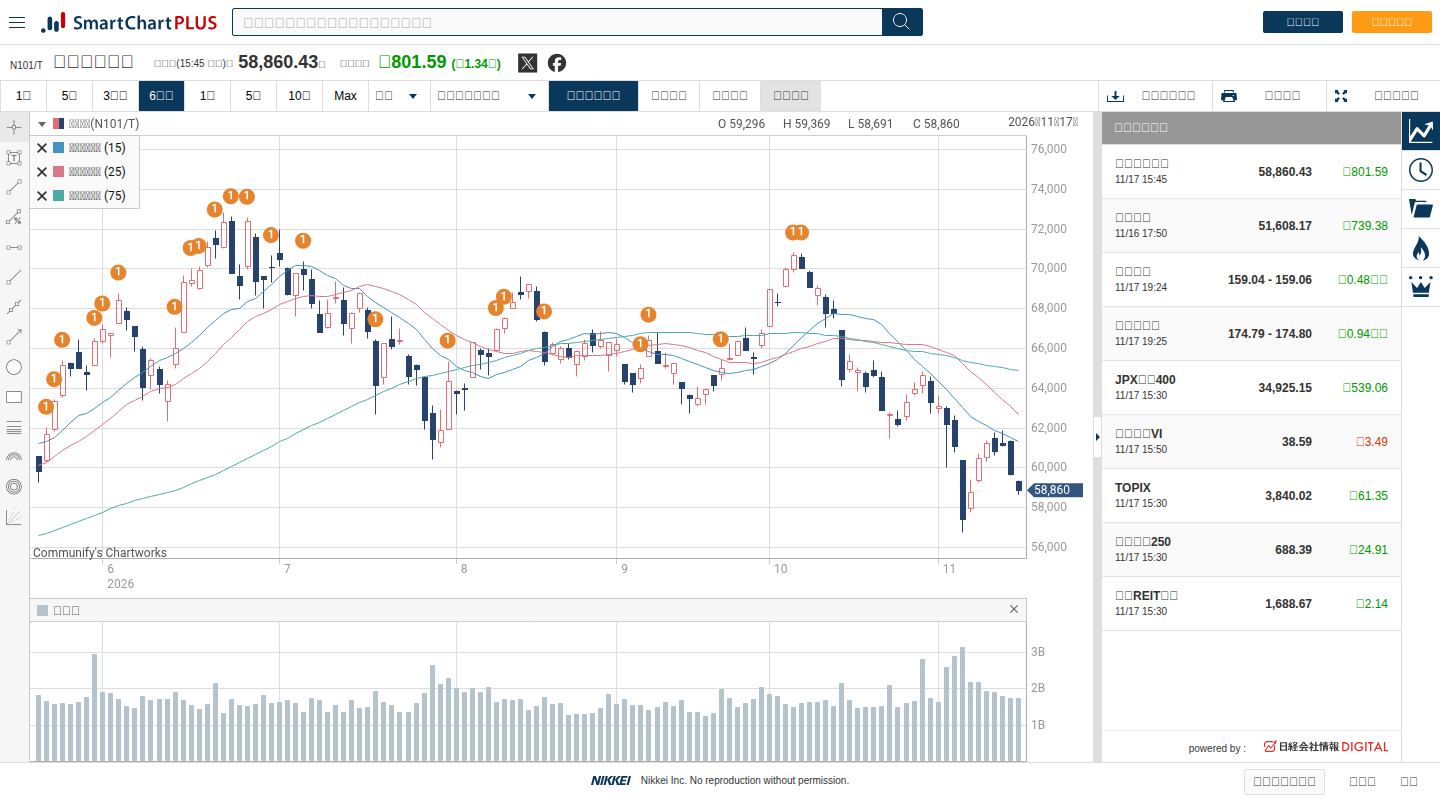

In [7]:
from IPython.display import display, Image

driver.set_window_size(1440, 1000)

driver.save_screenshot("nikkei_chart.png")

display(Image(filename="nikkei_chart.png"))

In [8]:
from selenium.webdriver.common.by import By

canvases = driver.find_elements(By.TAG_NAME, "canvas")

print("canvasの数:", len(canvases))

for i, canvas in enumerate(canvases):
    print(i, "幅:", canvas.size["width"],
          "高さ:", canvas.size["height"])

canvasの数: 4
0 幅: 1053 高さ: 464
1 幅: 1053 高さ: 464
2 幅: 1053 高さ: 141
3 幅: 1053 高さ: 141


In [9]:
from selenium.webdriver.common.action_chains import ActionChains

chart = canvases[0]

ActionChains(driver).move_to_element(chart).perform()

print("グラフの中央にマウスを移動しました")

グラフの中央にマウスを移動しました


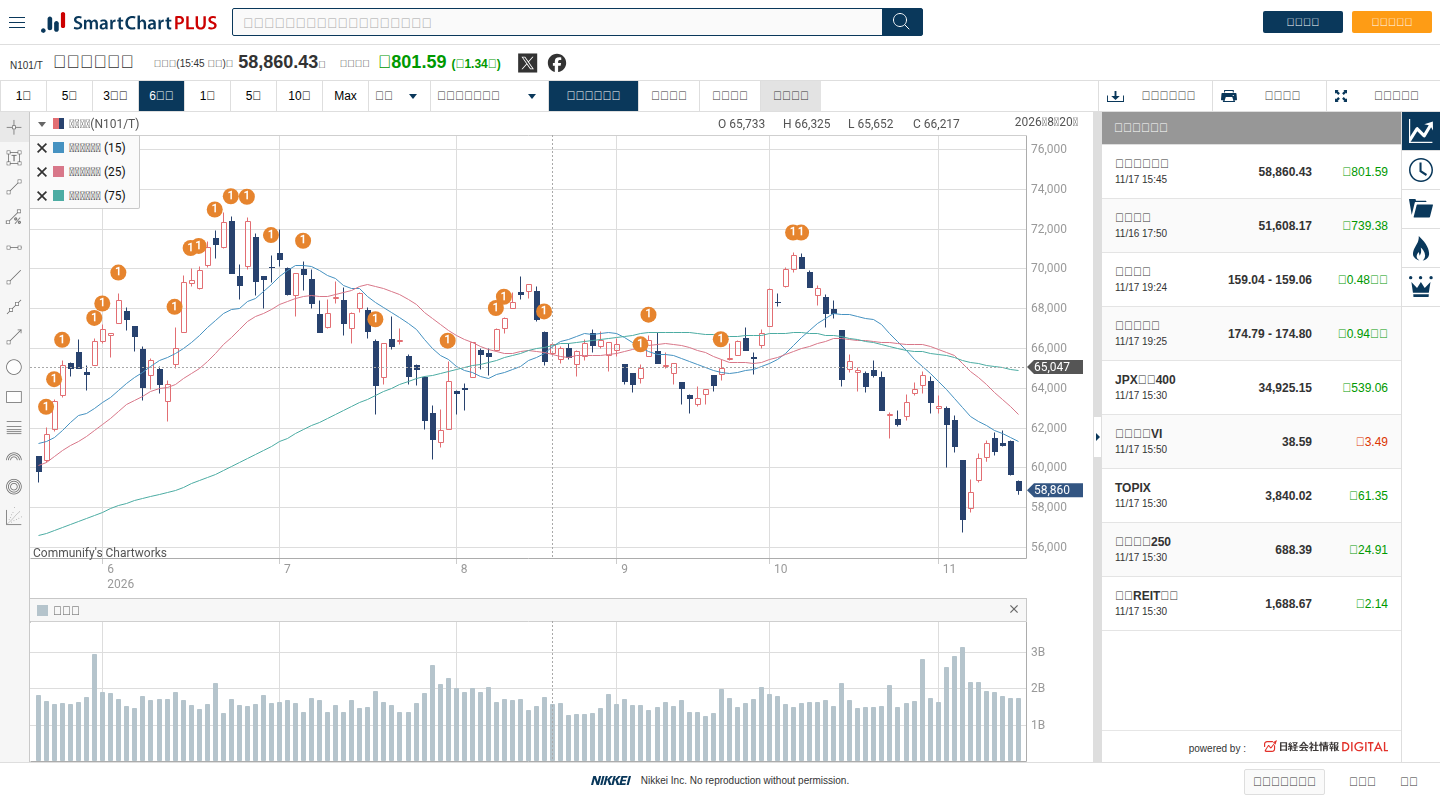

In [10]:
driver.save_screenshot("nikkei_hover.png")
display(Image(filename="nikkei_hover.png"))

In [11]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(driver.page_source, "html.parser")

text = soup.get_text(" ", strip=True)

print(text[:2000])

日経平均株価  : 指数 :  スマートチャートプラス : 日経電子版 「」に関連する項目が見つかりませんでした。 ログイン お申し込み N101/T 日経平均株価 現在値(15:45 大引)： 58,860.43 円 前日比： －801.59 (－1.34％) 1日（3分足） 5日（15分足） 3カ月（日足） 6カ月（日足） 1年（週足） 5年（月足） 10年（月足） 収録されているデータを全期間分表示します 期間 1日 1分足 3分足 5分足 15分足 5日 1分足 3分足 5分足 15分足 1時間足 1カ月 日足 3カ月 日足 6カ月 日足 週足 年初来 日足 週足 1年 日足 週足 3年 週足 月足 5年 週足 月足 10年 月足 20年 月足 Max テクニカル指標 上部パネルに表示 価格帯別売買高 高値・安値 単純移動平均 ボリンジャーバンド パラボリック 一目均衡表 下部パネルに表示 売買高 配当利回り ＲＳＩ ＤＭＩ ＭＡＣＤ ボリンジャーバンド %B ファストストキャスティックス スローストキャスティックス ニュース表示 関連ニュース 適時開示 大量保有 プレスリリース 配当履歴 株式分割・併合 銘柄比較 日経平均や閲覧した銘柄などと値動きを比較できます 詳細設定 テクニカル指標などの表示をカスタマイズ出来ます リセット 選択した表示条件をデフォルト設定に戻します ダウンロード 画面印刷 全画面表示 Remove Indicator 単純移動平均 (15) Remove Indicator 単純移動平均 (25) Remove Indicator 単純移動平均 (75) 2026年8月20日 C 66,217 L 65,652 H 66,325 O 65,733 日経平均(N101/T) その他3件 58,860 65,047 売買高 Communify's Chartworks 市場サマリー 閲覧履歴 銘柄フォルダ連携 注目株 ランキング 市場サマリー 日経平均株価 11/17 15:45 58,860.43 －801.59 ＮＹダウ 11/16 17:50 51,608.17 －739.38 ドル／円 11/17 19:24 159.04 - 159.06 －0.48円高 ユーロ／円 11/17 19:25 174.79 - 174.80 －0

In [12]:
html = driver.page_source

position = html.find("66,217")

print(html[position-300:position+300])

 visibility: visible;"><div class="chartworks-legend-timestamp" style="visibility: visible;">2026年8月20日</div>			<div class="chartworks-legend-ohlc-item" style="display: block; margin-right: inherit;">				<span class="chartworks-legend-ohlc-label-c">C</span>				<span class="chartworks-legend-ohlc-c">66,217</span>			</div>			<div class="chartworks-legend-ohlc-item" style="display: block;">				<span>L</span>				<span class="chartworks-legend-ohlc-l">65,652</span>			</div>			<div class="chartworks-legend-ohlc-item" style="display: block;">				<span>H</span>				<span class="chartworks-legend-ohlc-h


In [13]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(driver.page_source, "html.parser")

date_element = soup.select_one(".chartworks-legend-timestamp")

print(date_element.get_text(strip=True))

2026年8月20日


In [14]:
ohlc_elements = soup.select(".chartworks-legend-ohlc-item")

for element in ohlc_elements:
    print(element.get_text(" ", strip=True))

C 66,217
L 65,652
H 66,325
O 65,733


In [15]:
stock = {}

for element in ohlc_elements:
    parts = element.get_text(" ", strip=True).split()
    stock[parts[0]] = parts[1]

print(stock)

{'C': '66,217', 'L': '65,652', 'H': '66,325', 'O': '65,733'}


In [16]:
from datetime import datetime

date_text = date_element.get_text(strip=True)

date_obj = datetime.strptime(date_text, "%Y年%m月%d日")

formatted_date = date_obj.strftime("%Y-%m-%d")

print(formatted_date)

2026-08-20


In [19]:
from bs4 import BeautifulSoup
from datetime import datetime

def extract_stock_data(html):
    soup = BeautifulSoup(html, "html.parser")

    # 日付を取得して形式を変換
    date_element = soup.select_one(".chartworks-legend-timestamp")
    date_text = date_element.get_text(strip=True)
    date_obj = datetime.strptime(date_text, "%Y年%m月%d日")
    formatted_date = date_obj.strftime("%Y-%m-%d")

    # 始値・高値・安値・終値を取得
    ohlc_elements = soup.select(".chartworks-legend-ohlc-item")

    stock = {}
    for element in ohlc_elements:
        parts = element.get_text(" ", strip=True).split()
        stock[parts[0]] = parts[1]

    # 課題で指定された順番に並べる
    result = [
        formatted_date,
        stock["O"],
        stock["H"],
        stock["L"],
        stock["C"]
    ]

    return result

In [20]:
stock_data = extract_stock_data(driver.page_source)

print(stock_data)

['2026-08-20', '65,733', '66,325', '65,652', '66,217']


In [21]:
from selenium.webdriver.common.action_chains import ActionChains

chart = canvases[0]

# グラフ中央へ移動
ActionChains(driver).move_to_element(chart).perform()

# 中央から右へ移動
chart_width = int(chart.size["width"])

ActionChains(driver).move_by_offset(
    chart_width // 2 - 5, 0
).perform()

print("グラフの右端付近に移動しました")

# 右端付近の株価を取得
print(extract_stock_data(driver.page_source))

グラフの右端付近に移動しました
['2026-08-20', '65,733', '66,325', '65,652', '66,217']


In [22]:
# グラフ中央に移動
ActionChains(driver).move_to_element(chart).perform()

# 中央から左へ150px移動
ActionChains(driver).move_by_offset(-150, 0).perform()

# その位置の株価を取得
print(extract_stock_data(driver.page_source))

['2026-07-24', '65,584', '65,721', '64,201', '64,611']


In [23]:
# グラフ中央へマウスを戻す
ActionChains(driver).move_to_element(chart).perform()

# 5pxずつではなく、1pxずつ5回移動
for i in range(5):
    ActionChains(driver).move_by_offset(-1, 0).perform()

    stock_data = extract_stock_data(driver.page_source)

    print(stock_data)

['2026-08-20', '65,733', '66,325', '65,652', '66,217']
['2026-08-20', '65,733', '66,325', '65,652', '66,217']
['2026-08-20', '65,733', '66,325', '65,652', '66,217']
['2026-08-20', '65,733', '66,325', '65,652', '66,217']
['2026-08-20', '65,733', '66,325', '65,652', '66,217']


In [24]:
from selenium.webdriver.common.action_chains import ActionChains

# グラフ中央に移動
ActionChains(driver).move_to_element(chart).perform()

stock_values = []
last_date = None

for i in range(50):
    # 1pxずつ左へ移動
    ActionChains(driver).move_by_offset(-1, 0).perform()

    # 現在のマウス位置の株価を取得
    stock_data = extract_stock_data(driver.page_source)

    # 前回と違う日付だけ保存
    if stock_data[0] != last_date:
        stock_values.append(stock_data)
        last_date = stock_data[0]

for data in stock_values:
    print(data)

['2026-08-20', '65,733', '66,325', '65,652', '66,217']
['2026-08-19', '66,812', '66,834', '65,134', '65,326']
['2026-08-18', '68,847', '69,093', '67,369', '67,461']
['2026-08-17', '68,882', '69,226', '68,492', '69,220']
['2026-08-14', '68,811', '69,608', '68,471', '68,714']
['2026-08-13', '68,033', '68,800', '68,006', '68,309']
['2026-08-12', '66,994', '67,569', '66,736', '67,524']


In [26]:
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

def get_stock_values(driver, url, scan_width=100):
    # Webページを開く
    driver.get(url)

    # 株価の日付が表示されるまで待つ
    WebDriverWait(driver, 30).until(
        EC.visibility_of_element_located(
            (By.CSS_SELECTOR, ".chartworks-legend-timestamp")
        )
    )

    # 株価グラフを取得
    chart = driver.find_elements(By.TAG_NAME, "canvas")[0]
    chart_width = int(chart.size["width"])

    # グラフ中央から右端付近へ移動
    ActionChains(driver).move_to_element(chart).perform()
    ActionChains(driver).move_by_offset(
        chart_width // 2 - 20, 0
    ).perform()

    stock_values = []
    last_date = None

    # 右から左へ1pxずつ移動
    for i in range(scan_width):
        ActionChains(driver).move_by_offset(-1, 0).perform()

        stock_data = extract_stock_data(driver.page_source)

        if stock_data[0] != last_date:
            stock_values.append(stock_data)
            last_date = stock_data[0]

    return stock_values

In [27]:
stock_values = get_stock_values(driver, url, 100)

print("取得日数:", len(stock_values))

for data in stock_values:
    print(data)

取得日数: 9
['2026-08-20', '65,733', '66,325', '65,652', '66,217']
['2026-11-17', '59,296', '59,369', '58,691', '58,860']
['2026-11-16', '61,348', '61,389', '59,631', '59,662']
['2026-11-13', '61,223', '61,903', '61,082', '61,142']
['2026-11-12', '61,475', '61,788', '60,644', '60,819']
['2026-11-11', '60,525', '61,391', '60,318', '61,249']
['2026-11-10', '59,372', '60,744', '59,268', '60,460']
['2026-11-09', '57,961', '59,440', '57,775', '58,776']
['2026-11-06', '60,374', '60,374', '56,746', '57,435']


In [30]:
from selenium.webdriver.common.by import By
from selenium.webdriver.common.action_chains import ActionChains

# ページの再読み込み等によって要素が無効化されているため、再度取得し直します
chart = driver.find_elements(By.TAG_NAME, "canvas")[0]

# グラフ中央へ移動
ActionChains(driver).move_to_element(chart).perform()

# 中央から右端へ移動
ActionChains(driver).move_by_offset(
    chart.size["width"] // 2 - 20, 0
).perform()

# 現在位置の株価データを取得・表示
print(extract_stock_data(driver.page_source))


['2026-08-20', '65,733', '66,325', '65,652', '66,217']


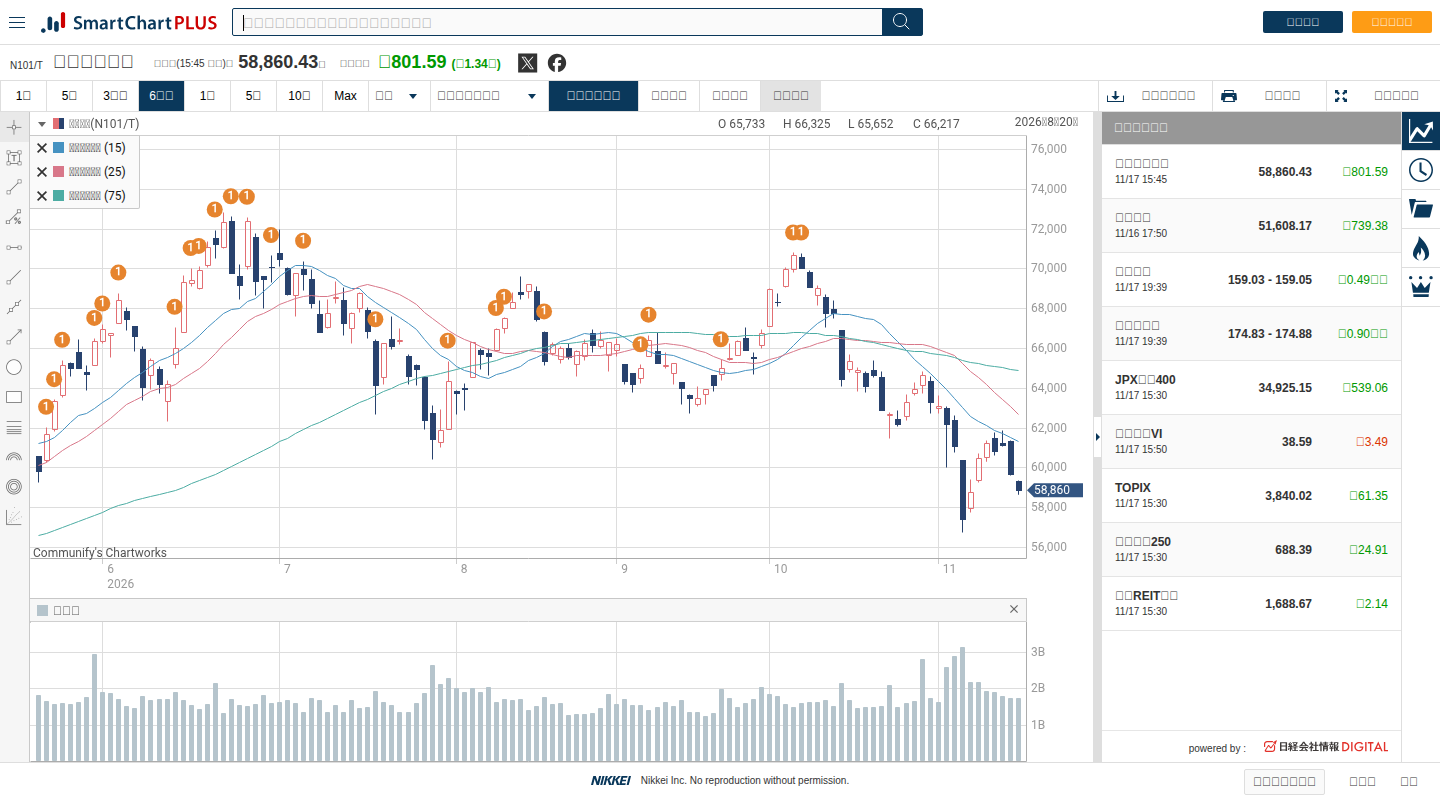

取得データ: ['2026-08-20', '65,733', '66,325', '65,652', '66,217']


In [31]:
import time

time.sleep(1)

driver.save_screenshot("nikkei_right.png")
display(Image(filename="nikkei_right.png"))

print("取得データ:", extract_stock_data(driver.page_source))

In [33]:
from selenium.webdriver.common.action_chains import ActionChains

chart = driver.find_elements(By.TAG_NAME, "canvas")[0]

ActionChains(driver).move_to_element_with_offset(
    chart, 480, 0
).perform()

print(extract_stock_data(driver.page_source))

['2026-11-05', '62,385', '62,654', '60,786', '61,078']


In [34]:
for x in [350, 400, 450]:
    ActionChains(driver).move_to_element_with_offset(
        chart, x, 0
    ).perform()

    print(x, extract_stock_data(driver.page_source)[0])

350 2026-10-27
400 2026-11-05
450 2026-11-16


In [35]:
for x in [455, 460, 465]:
    ActionChains(driver).move_to_element_with_offset(
        chart, x, 0
    ).perform()

    print(x, extract_stock_data(driver.page_source)[0])

455 2026-11-16
460 2026-11-17
465 2026-11-17


In [36]:
# グラフ右端付近に移動
ActionChains(driver).move_to_element_with_offset(
    chart, 465, 0
).perform()

stock_values = []
last_date = None

# 右から左へ1pxずつ20回移動
for i in range(20):
    ActionChains(driver).move_by_offset(-1, 0).perform()

    stock_data = extract_stock_data(driver.page_source)

    if stock_data[0] != last_date:
        stock_values.append(stock_data)
        last_date = stock_data[0]

for data in stock_values:
    print(data)


['2026-11-17', '59,296', '59,369', '58,691', '58,860']
['2026-11-16', '61,348', '61,389', '59,631', '59,662']
['2026-11-13', '61,223', '61,903', '61,082', '61,142']


In [37]:
ActionChains(driver).move_to_element_with_offset(
    chart, 465, 0
).perform()

stock_values = []
last_date = None

for i in range(900):
    ActionChains(driver).move_by_offset(-1, 0).perform()

    stock_data = extract_stock_data(driver.page_source)

    if stock_data[0] != last_date:
        stock_values.append(stock_data)
        last_date = stock_data[0]

print("取得日数:", len(stock_values))
print("最初のデータ:", stock_values[0])
print("最後のデータ:", stock_values[-1])

取得日数: 113
最初のデータ: ['2026-11-17', '59,296', '59,369', '58,691', '58,860']
最後のデータ: ['2026-06-03', '67,239', '68,786', '67,239', '68,402']


In [38]:
import time

start = time.perf_counter()

# ここに株価取得処理を入れる

end = time.perf_counter()

print("処理時間:", round(end - start, 2), "秒")

処理時間: 0.0 秒


In [39]:
import time

start = time.perf_counter()

# グラフ右端付近に移動
ActionChains(driver).move_to_element_with_offset(
    chart, 465, 0
).perform()

stock_values = []
last_date = None

for i in range(900):
    ActionChains(driver).move_by_offset(-1, 0).perform()

    stock_data = extract_stock_data(driver.page_source)

    if stock_data[0] != last_date:
        stock_values.append(stock_data)
        last_date = stock_data[0]

end = time.perf_counter()

print("取得日数:", len(stock_values))
print("処理時間:", round(end - start, 2), "秒")

取得日数: 113
処理時間: 310.37 秒


In [40]:
def get_stock_values(driver, url):
    # 日経新聞のページを開く
    driver.get(url)

    # グラフが表示されるまで待つ
    wait = WebDriverWait(driver, 30)
    wait.until(
        EC.visibility_of_element_located(
            (By.CSS_SELECTOR, ".chartworks-legend-timestamp")
        )
    )

    # グラフを取得
    chart = driver.find_elements(By.TAG_NAME, "canvas")[0]

    # グラフの中央から右端付近へ移動
    ActionChains(driver).move_to_element_with_offset(
        chart, 465, 0
    ).perform()

    stock_values = []
    last_date = None

    # 1pxずつ左へ移動
    for i in range(900):
        ActionChains(driver).move_by_offset(-1, 0).perform()

        stock_data = extract_stock_data(driver.page_source)

        if stock_data[0] != last_date:
            stock_values.append(stock_data)
            last_date = stock_data[0]

    return stock_values

In [41]:
import time

url = "https://www.nikkei.com/smartchart/?code=N101/T&timeframe=6m&interval=1Day&eventsShow=1"

# 開始時間を記録
start = time.perf_counter()

# 株価データを取得
stock_values = get_stock_values(driver, url)

# 終了時間を記録
end = time.perf_counter()

# 結果を表示
for data in stock_values:
    print(data)

print("取得日数:", len(stock_values))
print("処理時間:", round(end - start, 2), "秒")

['2026-11-17', '59,296', '59,369', '58,691', '58,860']
['2026-11-16', '61,348', '61,389', '59,631', '59,662']
['2026-11-13', '61,223', '61,903', '61,082', '61,142']
['2026-11-12', '61,475', '61,788', '60,644', '60,819']
['2026-11-11', '60,525', '61,391', '60,318', '61,249']
['2026-11-10', '59,372', '60,744', '59,268', '60,460']
['2026-11-09', '57,961', '59,440', '57,775', '58,776']
['2026-11-06', '60,374', '60,374', '56,746', '57,435']
['2026-11-05', '62,385', '62,654', '60,786', '61,078']
['2026-11-04', '62,973', '63,105', '60,030', '62,189']
['2026-11-02', '62,972', '63,615', '62,713', '63,082']
['2026-10-30', '64,344', '64,589', '62,711', '63,290']
['2026-10-29', '64,126', '64,831', '63,749', '64,659']
['2026-10-28', '63,739', '64,309', '63,660', '63,954']
['2026-10-27', '62,569', '63,685', '62,389', '63,268']
['2026-10-26', '62,450', '62,903', '62,094', '62,190']
['2026-10-23', '62,667', '62,787', '61,463', '62,693']
['2026-10-22', '64,539', '64,866', '62,908', '62,908']
['2026-10-

In [42]:
dates = [data[0] for data in stock_values]

print("取得件数:", len(dates))
print("重複を除いた件数:", len(set(dates)))

取得件数: 113
重複を除いた件数: 113
